<a href="https://colab.research.google.com/github/ShlokBagwe/Agri-AI-Bootcamp/blob/main/Agri_Day_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("patelris/crop-yield-prediction-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'crop-yield-prediction-dataset' dataset.
Path to dataset files: /kaggle/input/crop-yield-prediction-dataset


In [2]:
import os
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


files = [f for f in os.listdir(path) if f.endswith('.csv')]
csv_path = os.path.join(path, files[0])
df = pd.read_csv(csv_path)

In [3]:
df.head()

,Domain Code,Domain,Area Code,Area,Element Code,Element,Item Code,Item,Year Code,Year,Unit,Value
0,QC,Crops,2,Afghanistan,5419,Yield,56,Maize,1961,1961,hg/ha,14000
1,QC,Crops,2,Afghanistan,5419,Yield,56,Maize,1962,1962,hg/ha,14000
2,QC,Crops,2,Afghanistan,5419,Yield,56,Maize,1963,1963,hg/ha,14260
3,QC,Crops,2,Afghanistan,5419,Yield,56,Maize,1964,1964,hg/ha,14257
4,QC,Crops,2,Afghanistan,5419,Yield,56,Maize,1965,1965,hg/ha,14400


In [4]:
flag = df['Year'].is_monotonic_increasing
print(flag)

False


In [5]:
df.sort_values('Year', inplace=True)

In [6]:
X = df[['Area', 'Item', 'Year']]
y = df['Value']

In [7]:
import numpy as np
idx=np.random.default_rng(0).permutation(len(X))
cut=int(0.8*len(X)); tr,te=idx[:cut],idx[cut:]
print(y[tr].mean(), y[tr].var(), y[tr].std())

62275.39812223128 4619560608.8954115 67967.3495797461


In [8]:
x_raw = X['Year'].values
x_mean = x_raw[tr].mean()
x_std = x_raw[tr].std()


x = (x_raw[tr] - x_mean) / x_std
y_train = y.values[tr]

w = b = 0.0
lr = 0.01
losses = []

for e in range(500):
    err = w * x + b - y_train
    w -= lr * 2 * (err * x).mean()
    b -= lr * 2 * err.mean()
    loss = (err ** 2).mean()
    losses.append(loss)

print(f"Final w: {w:.4f}, b: {b:.4f}, loss: {loss:.5f}")

Final w: 9239.1327, b: 62210.4737, loss: 4533060040.97042


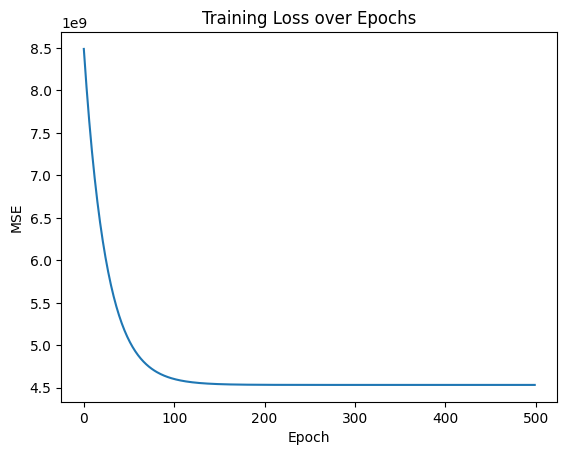

In [9]:
plt.plot(losses)
plt.title('Training Loss over Epochs')
plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.show()

In [10]:
rmse = np.sqrt(losses)
print(rmse[-5:])

[67328.00340264 67328.00340025 67328.00339795 67328.00339574
 67328.00339361]


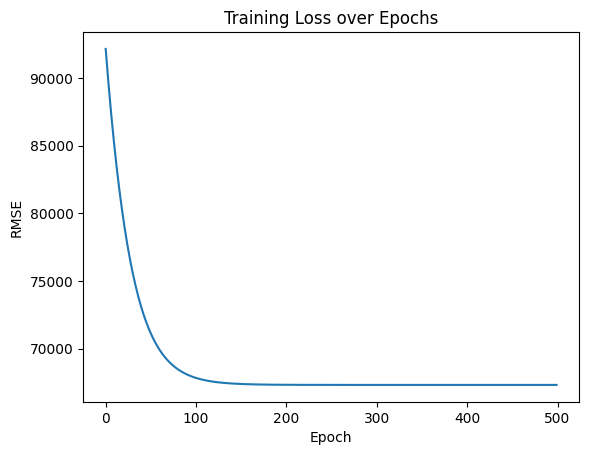

In [11]:
plt.plot(rmse)
plt.title('Training Loss over Epochs')
plt.xlabel('Epoch')
plt.ylabel('RMSE')
plt.show()

In [13]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV

X_encoded = pd.get_dummies(X, columns=['Area', 'Item'], drop_first=True)


gs = GridSearchCV(Ridge(), {"alpha": [0.01, 0.1, 1, 10, 100]}, cv=5).fit(X_encoded, y)
print(gs.best_params_)

{'alpha': 10}


In [14]:
X_train_final = X_encoded.iloc[tr]

y_train_final = y.iloc[tr]


ridge_model = Ridge(alpha=10.0)
ridge_model.fit(X_train_final, y_train_final)


print(f"Intercept: {ridge_model.intercept_:.4f}")

print(f"First 5 coefficients: {ridge_model.coef_[:5]}")

Intercept: -1118377.2111
First 5 coefficients: [   615.0801734   -3278.44830323  -6382.81413212 -46671.64966851
 -30882.17837452]


In [21]:
X_test_final = X_encoded.iloc[te]
y_test_final = y.iloc[te]

y_pred = ridge_model.predict(X_test_final)

In [24]:
from sklearn.metrics import mean_squared_error
mse = mean_squared_error(y_test_final, y_pred)

Final Test RMSE: 38949.7598


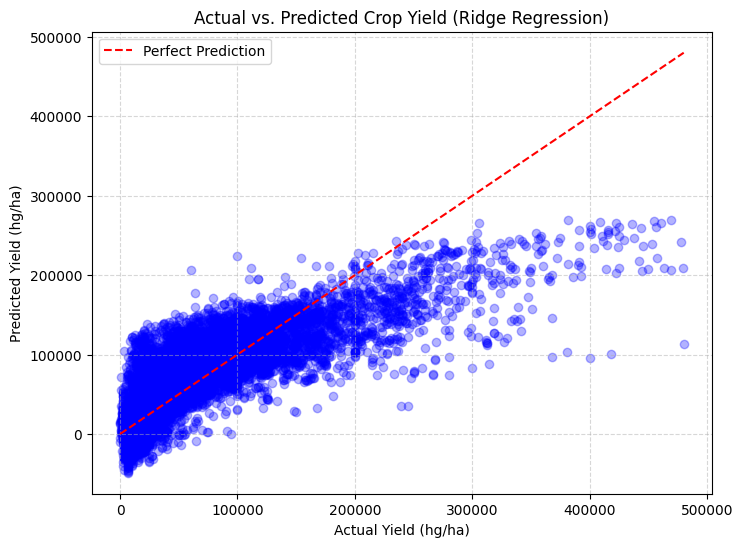

In [27]:
rmse_final = np.sqrt(mse)
print(f"Final Test RMSE: {rmse_final:.4f}")


plt.figure(figsize=(8, 6))
plt.scatter(y_test_final, y_pred, alpha=0.3, color='blue')


lims = [0, max(y_test_final.max(), y_pred.max())]
plt.plot(lims, lims, color='red', linestyle='--', label='Perfect Prediction')


plt.title('Actual vs. Predicted Crop Yield (Ridge Regression)')
plt.xlabel('Actual Yield (hg/ha)')
plt.ylabel('Predicted Yield (hg/ha)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [29]:
from sklearn.metrics import r2_score


r2 = r2_score(y_test_final, y_pred)
print(f"R2 Score: {r2}")


R2 Score: 0.6654111435182897
